# Interferometer Analysis Code

## Overview of the analysis

This analysis code shows you how to extract a plot of change in refractive index vs y position along a single vertical line in your image.

This codes assumes:
- the fringes are vertical

The simplest way to analyse your image is to take a single image and assume that the upper region of the image has zero fringe shift.

## Step 1: Load your image(s) on ImageJ

To extract the relevant frames of your video recordings you can use a computer programme called **ImageJ** — a free software which you should find installed on all Imperial computers via the Software Hub.

#### To load an image:
1. Open ImageJ and load the .TIF file.

#### To load a video and select frames for your analysis:
1. Open ImageJ and load the .TIF file. You can play the movie using the play button in the bottom left, or advance one frame at a time.
2. Find a clear frame with the gas jet present, and *Image > Duplicate*, choosing a sensible file name like "jet_1.TIF".

**If you want to analyse two images at the same time, e.g. one with a jet and one without, then:**

3. Find another frame without the gas jet and *Image > Duplicate*, choosing a sensible filename like "background_1.TIF".



## Step 2: Determine the fringe width

In this step, we want to find out the width of an unshifted fringe. In Sec 9.3.2 in the Lab Manual, this is called inter-fringe spacing ($P$).

<div>
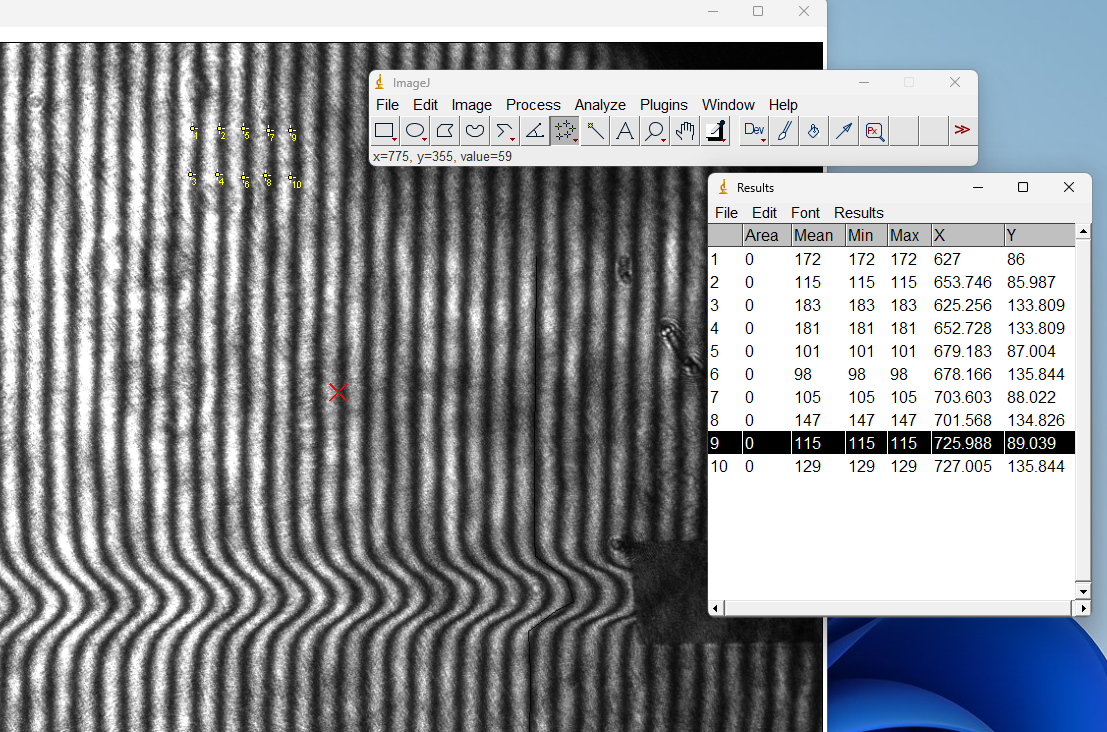
</div>

On your background (zero fringe shift region), you want to:

1. On the ImageJ menu choose *Multi-point* tool
2. Add several points to the image to best measure the fringe width. 
3. Once added, click *Analyze > Measure*. It should show you the XY coordinates for your points in pixels (check this!)
4. On the Results window, click *File > Save As* and save the data as an Excel spreadsheet
5. Find your fringe width in pixels. You can analyse this in excel or Python.

Note, you will want to expand this code to consider any errors and uncertainties in your measurement. Ultimately, you want to find, $P = \bar{P}\pm\sigma_P$.

#### Camera dimensions

The camera dimensions are:
$$
6.66~\text{mm} \times 5.32~\text{mm (H}\times\text{ V)} \\
1280 \times 1024~\text{pixels}
$$

Make sure your units are correct in ImageJ. You can change the scale using *Analyze>Set Scale*, if needed.


*****

**TO DO: Input your fringe width in pixels below**

*****



In [2]:
fringe_width_in_pixels =  63.652

# 1280 pixels = 6.66 mm
pixels_to_mm = 6.66 / 1280

fringe_width_in_mm = pixels_to_mm * fringe_width_in_pixels

print("Fringe width = " + str(round(fringe_width_in_mm,3)) + " mm" )

Fringe width = 0.331 mm


## Step 3: Trace a fringe path

Now, we want to find the fringe shift caused by the gas jet. To do this, we will follow a fringe from the top of the image, to the middle of the gas jet.

Make sure:
- your first point in the line is in an unshifted region
- you have a point on the axis of the gas jet. This will be yous "chord 0"

<div>
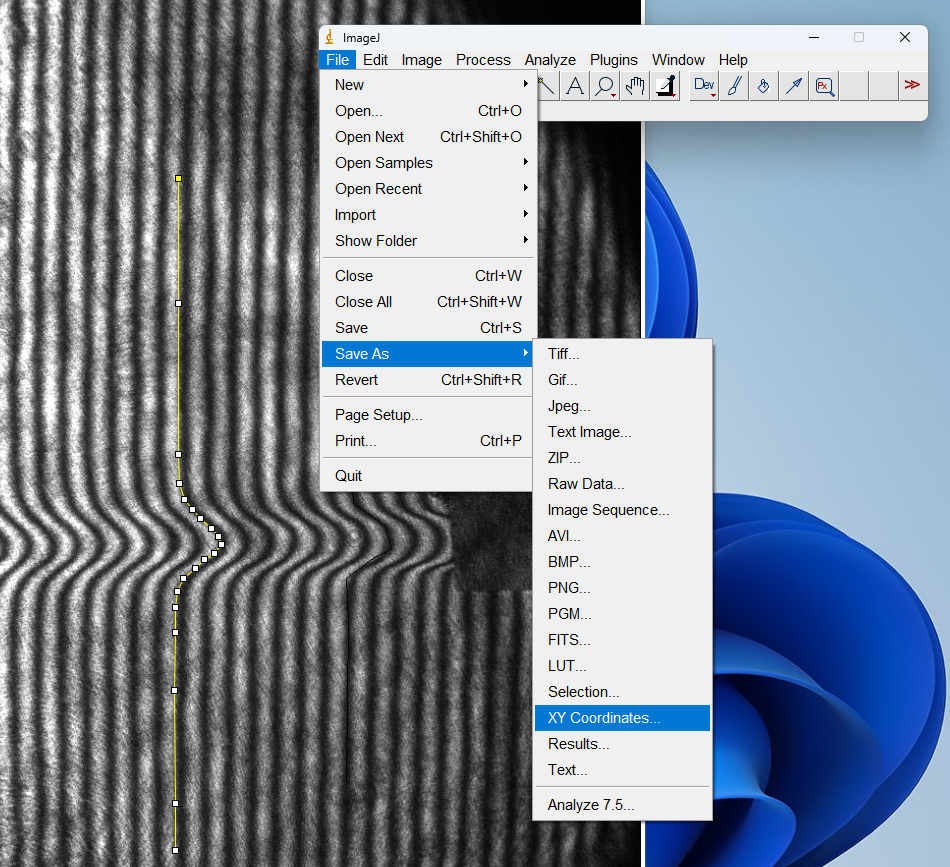
</div>


You can do this in ImageJ as follows:


**If you are analysing two separate images, first, you will want to:**

1. On the menu bar click *Analyze > Tools > Synchronize Windows*.
2. Highlight your plume and reference images in the small window that appears. Then arrange the two images so you can see them both at the same time.


**Then, or if you are using just one image:**

3. On the main ImageJ menu, right click (or long left click) the line drawing tool and choose *Segmented Line*. 
4. You can now drop anchor points to trace the path of the fringes, which will be marked simultaneously on both displays. Make sure your first point is in the unshifted region, and you have one point on the axis of the jet.
5. Once you have finished your line, click *File > Save As > XY Coordinates*. This will save the positions of your anchor points in pixels.

## Step 4: Load the XY coordinates into Python

This code loads your saved XY coordinates directly from the .TXT file saved in the step above

******

** TO DO: put your .txt file name below **

******

In [3]:
# load libraries
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
file_name =  interferometer_xy.txt

data = np.loadtxt(file_name, delimiter="\t")

x = data[:, 0] # x positions in pixels
y = data[:, 1] # y positions in pixels

In [ ]:
print(x)
print(y)

In [ ]:
plt.plot(x,y)
plt.xlabel('x position (pixels)')
plt.ylabel('y position (pixels)')
plt.show()

## Step 5: Convert into relevant units

We want x to be in units of fringe shift and y to be in mm.

For our calculation of density, we only need points where $y\geq0$, where $y=0$ is on the axis of the jet 

In [ ]:
# We want x to be in units of fringe shift

# The first point on the segmented line is in an unshifted region. 
# This point defines a fringe shift of 0
ref_x = x[0] 

Delta_x = x - ref_x # Convert x into shift in pixels

Delta_F = (Delta_x / fringe_width_in_pixels)  # Convert Delta_x into fringe shift

In [ ]:
# We want y to be in units of mm
# We will define the axis of the jet to be y=0 (chord 0)

# choose the max fringe shift to define y=0
# you can edit this if you need to
y0 = y[np.where(Delta_F == max(Delta_F))[0]] 

y_mm = (y - y0) * pixels_to_mm

In [ ]:
plt.plot(y_mm,Delta_F)
plt.xlabel("y position (mm)")
plt.ylabel("Fringe shift")
plt.show()

In [ ]:
# for our density analysis, we only want y >= 0
# We also want y=0 to be the first position in the array y[0]

positions = np.where(y_mm >= 0)[0]

y_coordinates = np.abs(y_mm[positions])
fringe_shifts = Delta_F[positions]

In [ ]:
plt.plot(y_coordinates,fringe_shifts)
plt.xlabel('y position (mm)')
plt.ylabel('Fringe shift')
plt.show()

Before moving on:
- Check everything makes sense.
- Make a note of these values in your lab book.

We will now analyse this data.

## Step 6: Import into onion peeling method

#### Inputs
The inputs are:
- An array of chord positions, y(mm). Note, y[0]=0.
- An array of fringe shifts, F. Note, F[-1]=0

#### Variables
- $N_{\text{gas}}$: refractive index of butane (the gas jet) at ambient temperature and pressure
- $N_{\text{air}}$: refractive index of air at ambient temperature and pressure
- $x$: path length matrix, where $x_{i,j}$ is the length of the chord $i$ inside ring $j$ (in mm)
- $F$: measured fringe shift along each chord (from above)
- $\theta$: phase difference along each chord, $\theta=2\pi F$
- $\lambda$: probing wavelength (in mm)

#### Physics
The fringe shift on chord $i$:
$$
F_i = \frac{1}{\lambda}\sum_j x_{i,j} \Delta N_j
$$
where $\Delta N_j = N_j - N_{\text{air}}$ is the change in refractive index in ring $j$, and $x_{i,j}$ is the path length along chord $i$ through ring $j$. See Sec. 9.3.3 in Lab Manual.

Read through carefully what each function does. You do not need to edit them if your data is formatted in the expected way.

In [ ]:
Lambda = (532e-9)*(1e3)  # probing wavelength (in mm)
T = 293.15               # ambient temperature (K)
P = 101325.0             # ambient pressure (Pa)

# Refractive index at 0 degC, 1 atm, scaled to ambient conditions
# Assume (n-1) is proportional to gas density
scale = (P / 101325.0) * (273.15 / T)
# N_butane = 1 + 1.29e-3 * scale
N_gas = 1 + 1.0023e-3 * scale
N_air = 1 + 2.93e-4 * scale

In [ ]:
print(N_butane)
print(N_air)
print(N_gas - N_air)

In [ ]:
# This function finds the radius of each rings (r1, r2, r3,...)
# r0 = (y1-y0)/2, r2 = (y2-y1)/2, etc.
# See Fig. 9.3.2 in Lab Manual
def find_radius_values(y):
    radius_values = np.zeros(len(y)+1)
    radius_values[1:-1] = 0.5 * (y[:-1]+y[1:])
    radius_values[-1] = y[-1] + 0.5 * (y[-1] - y[-2])
    return radius_values

# This function finds x_ij
# x_ij is the length of chord i (at y_i) inside ring j
# See Fig. 9.3.3 in Lab Manual
def find_path_length_matrix(y,r):
    N = len(y)
    x = np.zeros((N,N))
    for i in range(N):
        for j in range(i,N):
            a, b = r[j],r[j+1]
            x[i,j] = 2 * (np.sqrt(max(b**2 - y[i]**2,0.0)) - np.sqrt(max(a**2 - y[i]**2,0.0))) 
            
    return x

# this function finds change in refractive index, dN_i
# see Eq. (9.11) in Lab Manual
def find_delta_N(y,F,Lambda):
    N = len(y)
    dn = np.zeros(N)
    
    # optical path distance (m)
    opd = F * Lambda 
    
    # find path lengths
    r = find_radius_values(y)
    x = find_path_length_matrix(y,r)
    
    # dN_i = (opd_i - sum{j>i}x_ij * dn_j)/x_ii (Eq 9.11)
    for i in range(N-1,-1,-1):
        dn[i] = (opd[i] - x[i,i+1:] @ dn[i+1:]) / x[i,i]
        
    return dn

In [ ]:
y_coordinates

In [ ]:
find_radius_values(y_coordinates)

In [ ]:
# find change in refractive index
dn = find_delta_N(y_coordinates,fringe_shifts,Lambda)

In [ ]:
plt.plot(y_coordinates,dn)
plt.xlabel("y position (mm)")
plt.ylabel("Change in refractive index, $\Delta N$")
plt.show()